<a href="https://colab.research.google.com/github/betzylopez-debug/Lab9_3_RNN_LSTM_RioMala/blob/main/Lab9_3_PracticaA_RioMala_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 9.3 — Práctica A con una cuenca nueva: río Mala en la estación La Capilla (CAMELS-PE)

**Alumna:** Betzy Camila Lopez Cerna

En clase el profesor aplicó RNN y LSTM a los caudales del río **Majes** (estación Huatiapa, `PE_204617`). En este trabajo repito la **Práctica A (A1 y A2)** con otra cuenca descargada de **CAMELS-PE**, el dataset del **SENAMHI** (Llauca et al., 2026).

**Cuenca elegida: río Mala, estación hidrométrica La Capilla (`PE_212900`)** — Lima, vertiente del Pacífico.

| Atributo (CAMELS-PE) | Valor |
|---|---|
| Ubicación de la estación | −12.52° S, −76.50° O, 399 msnm |
| Área de la cuenca | 2 124 km² |
| Rango de altitud | 399 – 5 870 msnm |
| Precipitación media | 1.24 mm/d (lluvias en DEF, estiaje en JJA) |
| Caudal medio | 0.68 mm/d |
| Índice de flujo base | 0.57 |
| Intervención humana | 5 pequeños embalses de riego (~2.2 hm³) |
| Registro de caudal | 1981–2025, 99% de días con dato |

¿Por qué Mala? Es una cuenca del Pacífico como Majes, pero **6 veces más pequeña**, con poca regulación por embalses y un registro de caudal casi completo. Así puedo comparar si la LSTM se comporta igual en otra cuenca.

In [1]:
# Paquetes principales
import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## 1. Descarga de los datos del SENAMHI (CAMELS-PE)

CAMELS-PE se publica en Zenodo (https://doi.org/10.5281/zenodo.20058778). El archivo ZIP trae una carpeta `03_timeseries/by_catchment/` con un CSV por estación. Descargo el ZIP y **extraigo solo el CSV de mi cuenca**.

En la versión 2.0 la precipitación PISCOp se llama `prec_pisco`; la renombro a `prec` .

> Si la descarga falla, se puede bajar el ZIP a mano desde Zenodo y subir el archivo `PE_212900.csv` a Colab (ícono de carpeta → subir).

In [2]:
GAUGE = 'PE_212900'                     # río Mala – estación La Capilla
ARCHIVO = f'{GAUGE}.csv'
URL_ZIP = 'https://zenodo.org/records/23890227/files/CAMELS-PE_v2.0.zip?download=1'
ZIP = 'CAMELS-PE_v2.0.zip'

if not os.path.exists(ARCHIVO):
    if not os.path.exists(ZIP):
        print('Descargando CAMELS-PE desde Zenodo (puede tardar unos minutos)...')
        urllib.request.urlretrieve(URL_ZIP, ZIP)
    with zipfile.ZipFile(ZIP) as z:
        nombre = [n for n in z.namelist() if n.endswith(f'by_catchment/{ARCHIVO}')][0]
        with open(ARCHIVO, 'wb') as f:
            f.write(z.read(nombre))
    print('Extraído:', nombre)

camels = pd.read_csv(ARCHIVO, parse_dates=['date'], index_col='date')
camels = camels.rename(columns={'prec_pisco': 'prec'})
camels = camels[['prec', 'tmin', 'tmean', 'tmax', 'srad', 'vprp', 'flow_obs', 'flow_sim']]
camels.to_csv(f'{GAUGE}_mala.csv')     # copia limpia (la subo también a GitHub)

print(f"Periodo: {camels.index.min().date()} a {camels.index.max().date()}  ({len(camels)} días)")
print(f"Días con caudal observado: {camels['flow_obs'].notna().sum()} ({camels['flow_obs'].notna().mean():.0%})")
camels.describe().T.round(2)

Descargando CAMELS-PE desde Zenodo (puede tardar unos minutos)...
Extraído: CAMELS-PE/03_timeseries/by_catchment/PE_212900.csv
Periodo: 1981-01-01 a 2025-12-31  (16436 días)
Días con caudal observado: 13762 (84%)


,count,mean,std,min,25%,50%,75%,max
prec,16436.0,1.24,2.16,0.00,0.02,0.16,1.57,18.80
tmin,16436.0,6.23,1.71,0.12,4.95,6.34,7.58,10.59
tmean,16436.0,12.36,0.94,8.73,11.77,12.40,12.98,15.74
tmax,16436.0,18.50,1.29,13.32,17.66,18.59,19.43,22.23
srad,16436.0,21.78,3.28,7.52,19.63,21.47,23.63,33.12
vprp,16436.0,8.24,1.93,2.74,6.64,8.54,9.90,12.40
flow_obs,13762.0,0.67,1.02,0.00,0.06,0.14,0.96,13.10
flow_sim,16436.0,0.64,0.97,0.00,0.06,0.13,0.96,13.10


## 2. Exploración y desempeño del modelo hidrológico del SENAMHI

Mismas métricas de clase: **NSE** (1 = perfecto, 0 = igual que predecir la media) y **KGE** (1 = perfecto; > −0.41 ya supera a la media). `flow_sim` es el caudal simulado por el modelo hidrológico del SENAMHI, que uso como referencia.

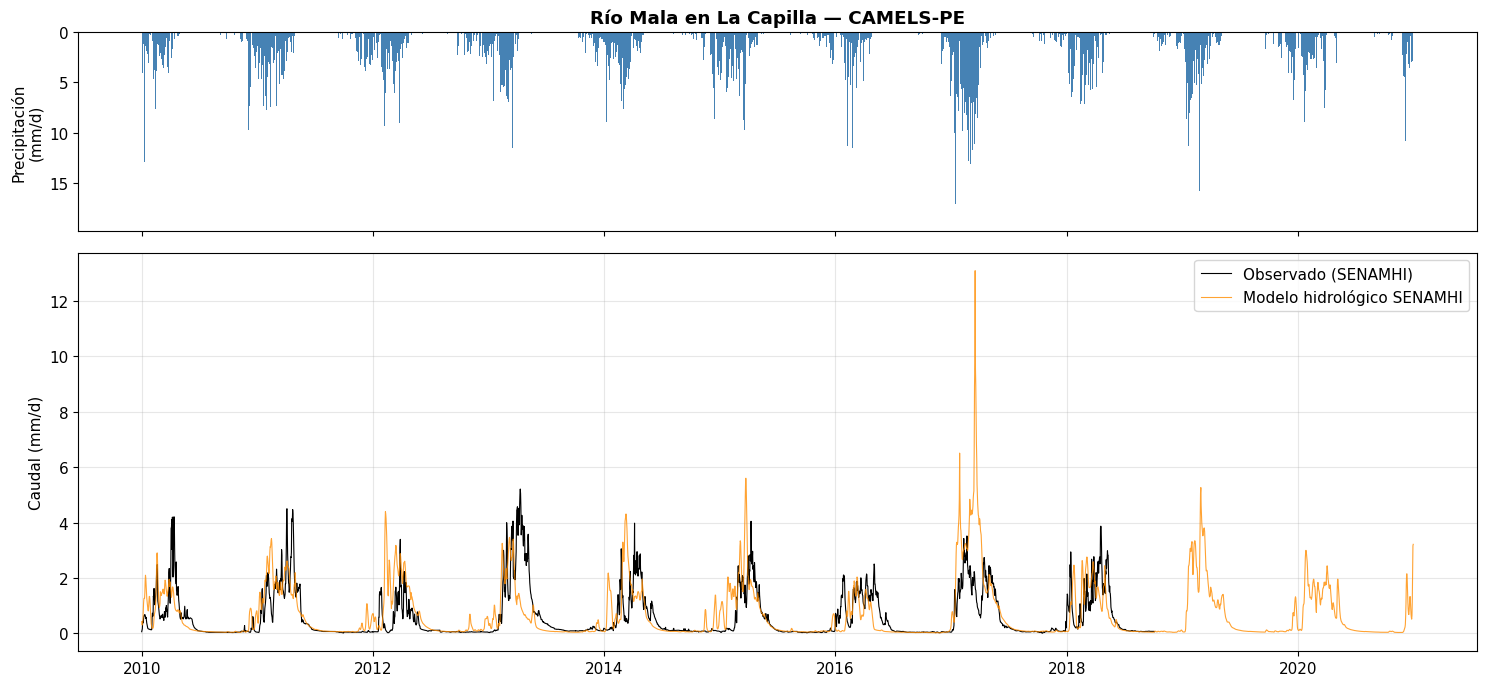

Desempeño del modelo hidrológico (solo días con caudal observado):
  1998–2010:  NSE =  0.220   KGE = 0.536
  2011–2015:  NSE =  0.089   KGE = 0.521
  2016–2020:  NSE = -0.785   KGE = 0.230


In [ ]:
def nse(obs, sim):
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)

fig, ejes = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
tramo = camels.loc['2010':'2020']
ejes[0].bar(tramo.index, tramo['prec'], width=1, color='steelblue')
ejes[0].invert_yaxis(); ejes[0].set_ylabel('Precipitación\n(mm/d)')
ejes[0].set_title('Río Mala en La Capilla — CAMELS-PE', fontweight='bold')
ejes[1].plot(tramo.index, tramo['flow_obs'], 'k-', lw=0.8, label='Observado (SENAMHI)')
ejes[1].plot(tramo.index, tramo['flow_sim'], '-', color='darkorange', lw=0.8, alpha=0.8, label='Modelo hidrológico SENAMHI')
ejes[1].set_ylabel('Caudal (mm/d)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print('Desempeño del modelo hidrológico (solo días con caudal observado):')
for ini, fin in [('1998', '2010'), ('2011', '2015'), ('2016', '2020')]:
    t = camels.loc[ini:fin].dropna(subset=['flow_obs'])
    print(f"  {ini}–{fin}:  NSE = {nse(t['flow_obs'], t['flow_sim']):6.3f}   KGE = {kge(t['flow_obs'], t['flow_sim']):.3f}")

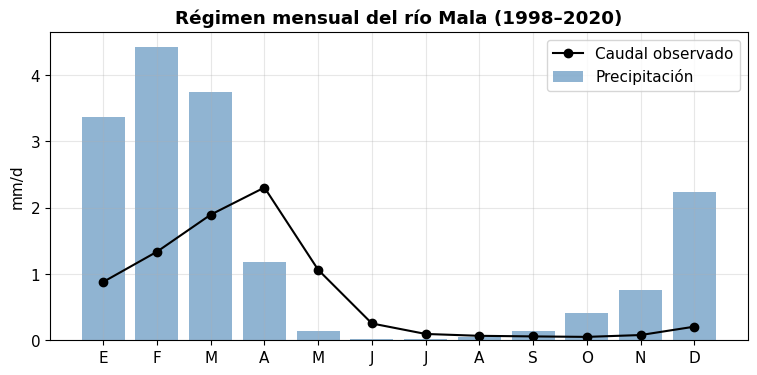

In [ ]:
# Extra: régimen mensual (para describir la cuenca)
mensual = camels.loc['1998':'2020'].groupby(camels.loc['1998':'2020'].index.month)[['prec', 'flow_obs']].mean()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(mensual.index, mensual['prec'], color='steelblue', alpha=0.6, label='Precipitación')
ax.plot(mensual.index, mensual['flow_obs'], 'ko-', label='Caudal observado')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['E','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_ylabel('mm/d'); ax.set_title('Régimen mensual del río Mala (1998–2020)', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3); plt.show()

### Preparación de los datos

- **Periodos:** entrenamiento **1998–2010**, validación **2011–2015** (*early stopping*) y prueba **2016–2020**.
- **Normalización** con la media y desviación del periodo de entrenamiento.
- **Logaritmo del caudal**, para que el modelo no ignore los caudales bajos del estiaje.
- **Huecos:** solo uso como objetivo los días con caudal observado. Agregué una línea que interpola si faltara algún dato meteorológico.

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

VARS_MET = ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
df = camels.loc['1996-01-01':'2020-12-31'].copy()   # 2 años extra para llenar las primeras ventanas
print('Datos meteorológicos faltantes:', int(df[VARS_MET].isna().sum().sum()))
df[VARS_MET] = df[VARS_MET].interpolate(limit_direction='both')   # por si hubiera algún hueco
entrena = df.index <= '2010-12-31'

X_met = df[VARS_MET].values.astype('float32')
X_met_n = (X_met - X_met[entrena].mean(0)) / X_met[entrena].std(0)

q_obs = df['flow_obs'].values
q_log = np.log(q_obs + 0.05)
q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
q_n = (q_log - q_media) / q_desv

def a_caudal(v):
    # De la escala normalizada-log de vuelta a mm/d
    return np.maximum(np.exp(np.asarray(v) * q_desv + q_media) - 0.05, 0)

def crear_ventanas(X, ventana, horizonte=0):
    # Ventanas que terminan en t; el objetivo es el caudal observado en t + horizonte
    t = np.arange(ventana - 1, len(X) - horizonte)
    t = t[~np.isnan(q_obs[t + horizonte]) & (df.index[t] >= '1998-01-01')]
    Xw = np.stack([X[i - ventana + 1:i + 1] for i in t])
    fechas = df.index[t + horizonte]
    periodos = {'entrena': fechas <= '2010-12-31',
                'valida': (fechas > '2010-12-31') & (fechas <= '2015-12-31'),
                'prueba': fechas >= '2016-01-01'}
    return Xw, t, fechas, periodos

def entrenar(capa, Xw, y, periodos, epocas=40):
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([keras.Input(shape=Xw.shape[1:]), capa,
                               layers.Dropout(0.2), layers.Dense(1)])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    e, v = periodos['entrena'], periodos['valida']
    t0 = time.time()
    hist = modelo.fit(Xw[e], y[e], epochs=epocas, batch_size=128, validation_data=(Xw[v], y[v]),
                      callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
                      verbose=0)
    print(f"  {capa.__class__.__name__:<10s} {len(hist.history['loss']):2d} épocas, {time.time() - t0:5.1f} s")
    return modelo, hist

Datos meteorológicos faltantes: 0


## A1 · Simulación lluvia–escorrentía: RNN vs. LSTM vs. modelo hidrológico

Entrada: **180 días** de las 6 variables meteorológicas → tensor `(muestras, 180, 6)`. Salida: el caudal del último día. El modelo **no ve el caudal**, solo el clima, igual que un modelo hidrológico.

In [4]:
VENTANA_SIM = 180
Xs, ts, fechas_s, per_s = crear_ventanas(X_met_n, VENTANA_SIM)
ys = q_n[ts].astype('float32')
print(f"Tensor de entrada: {Xs.shape}  → (muestras, días, variables)")
print({k: int(v.sum()) for k, v in per_s.items()})

print('Entrenando...')
rnn_sim, hist_rnn_sim = entrenar(layers.SimpleRNN(32), Xs, ys, per_s)
lstm_sim, hist_lstm_sim = entrenar(layers.LSTM(32), Xs, ys, per_s)

Tensor de entrada: (7352, 180, 6)  → (muestras, días, variables)
{'entrena': 4522, 'valida': 1821, 'prueba': 1009}
Entrenando...
  SimpleRNN  25 épocas,  22.6 s
  LSTM       18 épocas,  14.3 s


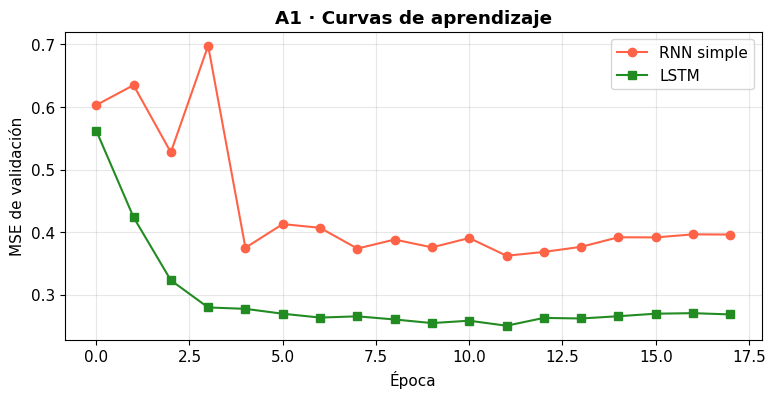

In [ ]:
# Extra: curvas de entrenamiento (pérdida de validación)
plt.figure(figsize=(9, 4))
plt.plot(hist_rnn_sim.history['val_loss'], 'o-', color='tomato', label='RNN simple')
plt.plot(hist_lstm_sim.history['val_loss'], 's-', color='forestgreen', label='LSTM')
plt.xlabel('Época'); plt.ylabel('MSE de validación'); plt.title('A1 · Curvas de aprendizaje', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Modelo (prueba 2016–2020)       NSE    KGE
------------------------------------------
Modelo hidrológico SENAMHI   -0.785  0.230
RNN simple                    0.534  0.623
LSTM                          0.292  0.310


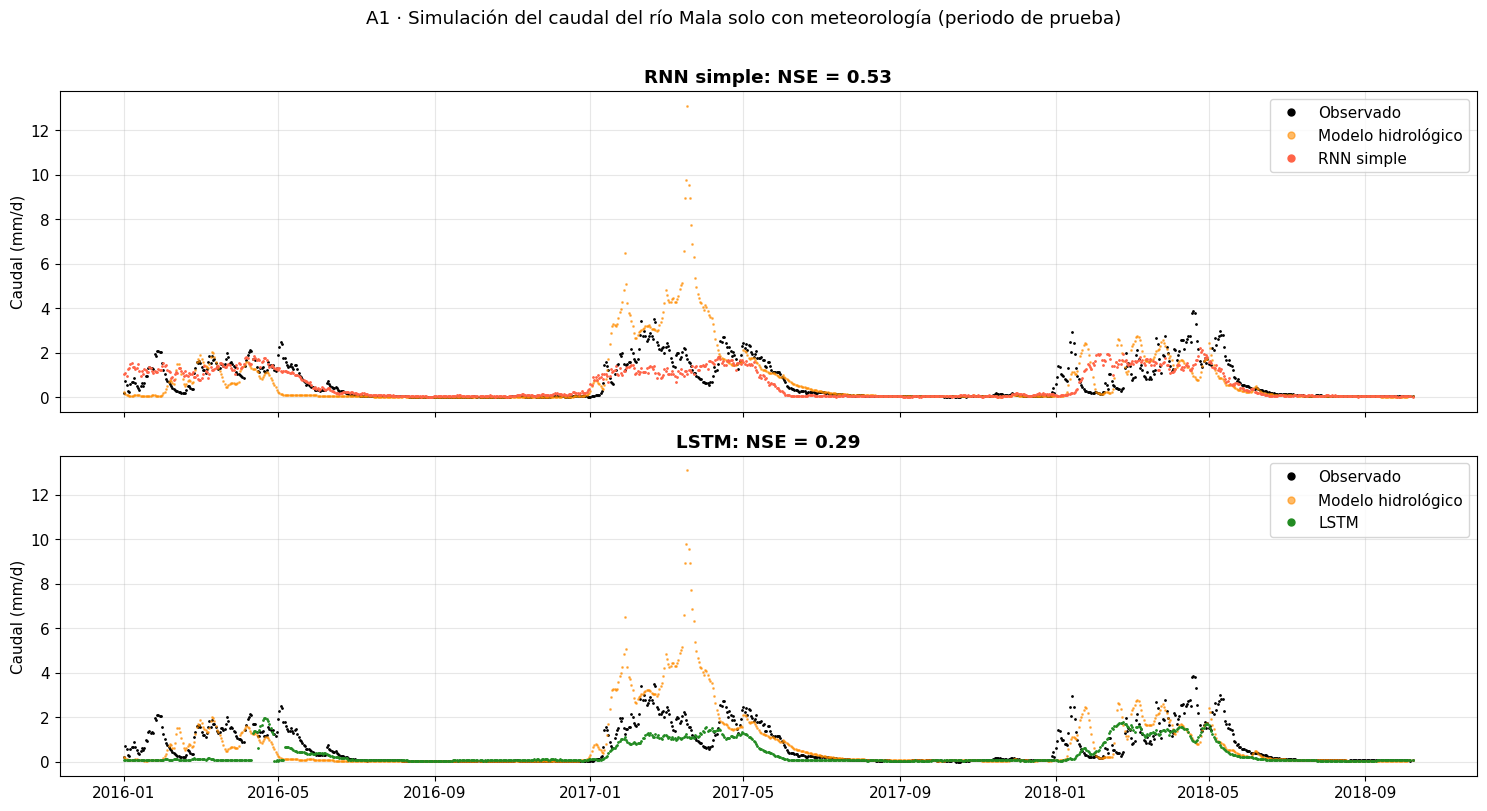

In [ ]:
p = per_s['prueba']
obs_te = q_obs[ts][p]
sim_hidro = df['flow_sim'].values[ts][p]
pred_rnn_sim = a_caudal(rnn_sim.predict(Xs[p], verbose=0).ravel())
pred_lstm_sim = a_caudal(lstm_sim.predict(Xs[p], verbose=0).ravel())

print(f"{'Modelo (prueba 2016–2020)':<28s} {'NSE':>6s} {'KGE':>6s}")
print('-' * 42)
for nombre, pred in [('Modelo hidrológico SENAMHI', sim_hidro),
                     ('RNN simple', pred_rnn_sim), ('LSTM', pred_lstm_sim)]:
    print(f"{nombre:<28s} {nse(obs_te, pred):6.3f} {kge(obs_te, pred):6.3f}")

fig, ejes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
f = fechas_s[p]
for ax, pred, nombre, color in [(ejes[0], pred_rnn_sim, 'RNN simple', 'tomato'),
                                (ejes[1], pred_lstm_sim, 'LSTM', 'forestgreen')]:
    ax.plot(f, obs_te, 'k.', ms=2, label='Observado')
    ax.plot(f, sim_hidro, '.', color='darkorange', ms=2, alpha=0.6, label='Modelo hidrológico')
    ax.plot(f, pred, '.', color=color, ms=2, label=nombre)
    ax.set_ylabel('Caudal (mm/d)'); ax.set_title(f'{nombre}: NSE = {nse(obs_te, pred):.2f}', fontweight='bold')
    ax.legend(markerscale=5); ax.grid(alpha=0.3)
plt.suptitle('A1 · Simulación del caudal del río Mala solo con meteorología (periodo de prueba)', y=1.01)
plt.tight_layout(); plt.show()

### ¿Qué observamos en A1?

- **LSTM:** NSE = 0.292, KGE = 0.310. **Modelo hidrológico del SENAMHI:** NSE = −0.785, KGE = 0.230. → La LSTM **supera** al modelo hidrológico en la prueba 2016–2020. El NSE negativo del modelo hidrológico significa que, en este periodo, simula peor que si solo predijera el caudal promedio.
- **RNN simple:** NSE = 0.534, KGE = 0.623. En esta cuenca la RNN simple fue **el mejor de los tres modelos**, lo contrario de lo que esperábamos por el gradiente desvaneciente. Una posible explicación es que Mala es una cuenca pequeña (2 124 km²) que responde rápido a la lluvia, así que la memoria de corto plazo de la RNN es suficiente. Además, los resultados dependen de una sola inicialización aleatoria y del *early stopping*: la LSTM pudo detenerse antes de aprender bien.
- **Comparación con Majes:** en Huatiapa la LSTM superó a la RNN simple y al modelo hidrológico. En Mala las dos redes superan al modelo hidrológico, pero la RNN queda por encima de la LSTM. Mala es 6 veces más pequeña y tiene menos regulación por embalses que Majes, así que su caudal depende más de la lluvia reciente y menos de la memoria larga.
- El NSE sigue siendo modesto en todos los modelos. El límite lo pone la calidad de la lluvia PISCOp que entra al modelo y el uso de agua para riego, que no está en las entradas.

## A2 · Pronóstico con asimilación del caudal observado

Ahora el modelo también recibe el caudal de los días anteriores (como en un centro de pronóstico):

- `q_entrada`: log-caudal observado; si falta, se usa el simulado.
- `q_bandera`: 1 si el dato es observado, 0 si es relleno.

La LSTM predice el **cambio** $\Delta = \log Q_{t+H} - \log Q_t$ a 1, 3 y 7 días, y se compara con la **persistencia** (suponer que el caudal no cambia).

In [ ]:
q_entrada = np.log(df['flow_obs'].fillna(df['flow_sim']).values + 0.05)
q_entrada_n = (q_entrada - q_media) / q_desv
q_bandera = df['flow_obs'].notna().values.astype('float32')
X_pron = np.column_stack([X_met_n, q_entrada_n, q_bandera]).astype('float32')

VENTANA_PRON = 90
resultados_pron = {}
for H in [1, 3, 7]:
    Xp, tp, fechas_p, per_p = crear_ventanas(X_pron, VENTANA_PRON, horizonte=H)
    base = q_entrada_n[tp]                            # último caudal conocido (escala normalizada)
    yp = (q_n[tp + H] - base).astype('float32')       # objetivo: el CAMBIO hasta t+H
    print(f'Horizonte {H} días:')
    modelo, _ = entrenar(layers.LSTM(32), Xp, yp, per_p)

    p = per_p['prueba']
    obs = q_obs[tp + H][p]
    pred = a_caudal(modelo.predict(Xp[p], verbose=0).ravel() + base[p])
    persist = a_caudal(base[p])
    resultados_pron[H] = {'fechas': fechas_p[p], 'obs': obs, 'LSTM': pred, 'Persistencia': persist,
                          'Hidrológico': df['flow_sim'].values[tp + H][p]}

print(f"\n{'Horizonte':<10s} {'LSTM':>7s} {'Persist.':>9s} {'Hidrol.':>8s}   (NSE, prueba 2016–2020)")
for H, r in resultados_pron.items():
    print(f"{H:>3d} días   " + ' '.join(f"{nse(r['obs'], r[m]):8.3f}" for m in ['LSTM', 'Persistencia', 'Hidrológico']))

Horizonte 1 días:
  LSTM       32 épocas,  14.9 s
Horizonte 3 días:
  LSTM       19 épocas,   9.5 s
Horizonte 7 días:
  LSTM       12 épocas,   6.1 s

Horizonte     LSTM  Persist.  Hidrol.   (NSE, prueba 2016–2020)
  1 días      0.947    0.946   -0.785
  3 días      0.817    0.810   -0.785
  7 días      0.655    0.642   -0.785


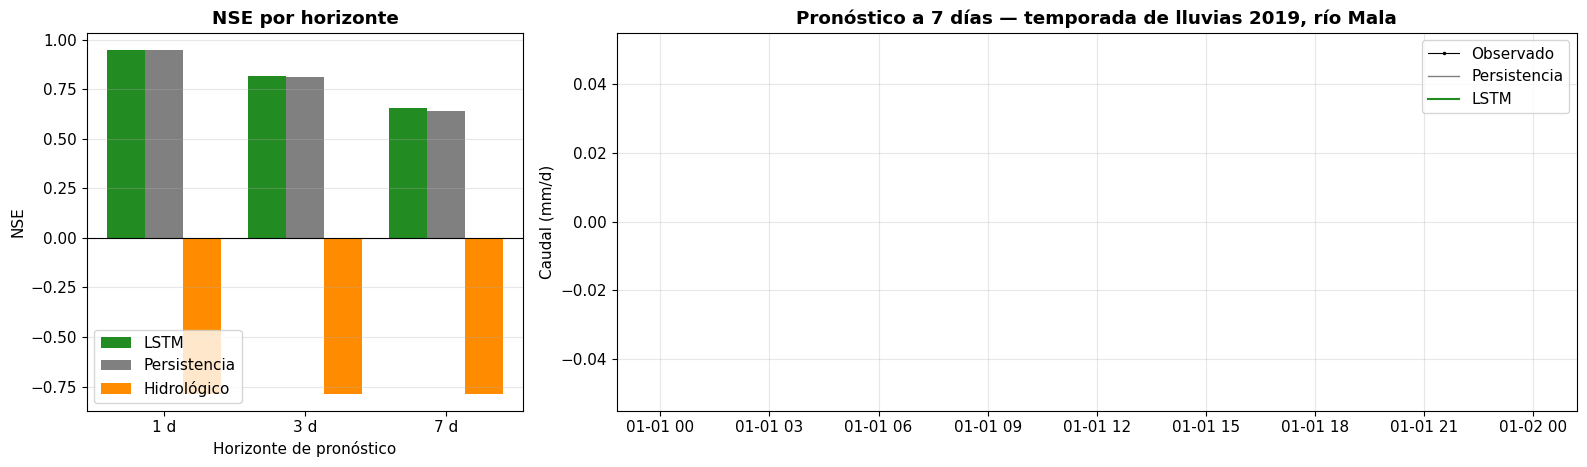

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 2.2]})
horizontes = list(resultados_pron)
ancho = 0.27
for k, (modelo_nombre, color) in enumerate([('LSTM', 'forestgreen'), ('Persistencia', 'gray'),
                                            ('Hidrológico', 'darkorange')]):
    valores = [nse(resultados_pron[H]['obs'], resultados_pron[H][modelo_nombre]) for H in horizontes]
    ejes[0].bar(np.arange(len(horizontes)) + (k - 1) * ancho, valores, ancho, color=color, label=modelo_nombre)
ejes[0].axhline(0, color='k', lw=0.8)
ejes[0].set_xticks(range(len(horizontes))); ejes[0].set_xticklabels([f'{H} d' for H in horizontes])
ejes[0].set_xlabel('Horizonte de pronóstico'); ejes[0].set_ylabel('NSE')
ejes[0].set_title('NSE por horizonte', fontweight='bold'); ejes[0].legend(); ejes[0].grid(axis='y', alpha=0.3)

r = resultados_pron[7]
tramo = (r['fechas'] >= '2019-01-01') & (r['fechas'] <= '2019-06-30')
ejes[1].plot(r['fechas'][tramo], r['obs'][tramo], 'k.-', ms=3, lw=0.8, label='Observado')
ejes[1].plot(r['fechas'][tramo], r['Persistencia'][tramo], '-', color='gray', lw=1, label='Persistencia')
ejes[1].plot(r['fechas'][tramo], r['LSTM'][tramo], '-', color='forestgreen', lw=1.5, label='LSTM')
ejes[1].set_ylabel('Caudal (mm/d)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
ejes[1].set_title('Pronóstico a 7 días — temporada de lluvias 2019, río Mala', fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
# Extra: tabla resumen de A2 con NSE y KGE
tabla = pd.DataFrame({f'{H} días': {f'{m} ({met})': f(r['obs'], r[m])
                                   for m in ['LSTM', 'Persistencia', 'Hidrológico']
                                   for met, f in [('NSE', nse), ('KGE', kge)]}
                      for H, r in resultados_pron.items()})
tabla.round(3)

,1 días,3 días,7 días
LSTM (NSE),0.947,0.817,0.655
LSTM (KGE),0.953,0.869,0.699
Persistencia (NSE),0.946,0.810,0.642
Persistencia (KGE),0.973,0.905,0.821
Hidrológico (NSE),-0.785,-0.785,-0.785
Hidrológico (KGE),0.230,0.230,0.230


### ¿Qué observamos en A2?

- Al darle el caudal observado, el NSE sube de **0.292** (LSTM en A1) a **0.947** (LSTM en A2, 1 día): la memoria del propio río es la información más valiosa a corto plazo.
- **A 1 día** la persistencia (NSE = **0.946**) es muy difícil de superar porque el río cambia poco de un día al otro. La LSTM (NSE = 0.947) prácticamente la iguala.
- **A 3–7 días** la LSTM (NSE = **0.817** a 3 días y **0.655** a 7 días) **supera ligeramente** a la persistencia (NSE = **0.810** y **0.642**). Sin embargo, la diferencia es pequeña, y en KGE la persistencia sale mejor (0.821 frente a 0.699 a 7 días). Esto indica que la LSTM tiende a suavizar los picos y a subestimar la variabilidad del caudal.
- Mientras más largo es el horizonte, todos los modelos empeoran, porque es más difícil anticipar lo que pasará en una semana.
- En el gráfico de 2019 la persistencia llega **7 días tarde** a cada pico, mientras que la LSTM reacciona antes a las subidas, aunque no llega a la altura completa de los picos.
- El modelo hidrológico (NSE = −0.785) queda muy por debajo de los dos, porque no usa el caudal observado.

## Conclusiones

1. Repetí la Práctica A con la cuenca del **río Mala (La Capilla, PE_212900)** usando datos de CAMELS-PE del SENAMHI.
2. En simulación (A1) las dos redes neuronales superaron al modelo hidrológico del SENAMHI (NSE = −0.785). Pero en esta cuenca la **RNN simple (NSE = 0.534)** fue mejor que la **LSTM (NSE = 0.292)**. Mala es una cuenca pequeña que responde rápido a la lluvia, así que la memoria larga de la LSTM no fue una ventaja, y el resultado también depende de la inicialización aleatoria.
3. En pronóstico (A2) asimilar el caudal observado mejora mucho los resultados (NSE de 0.29 a 0.95 a 1 día). La LSTM supera a la persistencia solo por un margen pequeño a 3–7 días, lo que muestra la importancia de comparar siempre con una línea base simple.
4. **Diferencias con Majes:** en Huatiapa la LSTM fue el mejor modelo en A1. En Mala ganó la RNN simple, posiblemente porque es una cuenca 6 veces más pequeña y con menos regulación por embalses, donde importa más la lluvia reciente que la memoria de largo plazo. En las dos cuencas el modelo hidrológico quedó por debajo de las redes neuronales, y en A2 la persistencia fue difícil de superar a 1 día.

**Referencias**
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M., & Lavado-Casimiro, W. (2026). *CAMELS-PE: Catchment Attributes and Meteorology for Large-sample Studies in Peru* [Data set]. Zenodo. https://doi.org/10.5281/zenodo.20058778
- Kratzert, F., Klotz, D., Brenner, C., Schulz, K., & Herrnegger, M. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *Hydrology and Earth System Sciences, 22*, 6005–6022.